In [1]:
!pip install git+https://github.com/microsoft/dowhy.git
import dowhy
from dowhy import CausalModel

import numpy as np
import pandas as pd
import graphviz
#import networkx as nx

np.set_printoptions(precision=3, suppress=True)


  Cloning https://github.com/microsoft/dowhy.git to /tmp/pip-req-build-x665tb6j
  Running command git clone --filter=blob:none --quiet https://github.com/microsoft/dowhy.git /tmp/pip-req-build-x665tb6j
  Resolved https://github.com/microsoft/dowhy.git to commit eb34218ef73da76a5731cbe49ab4f699be69fbb3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 10.7 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.8 MB/s  0:00:00
  Created wheel for dowhy: filename=dowhy-0.0.0-py3-none-any.whl size=436079 sha256=afd252ac9f0af99560a198a2534e2d73ec2c7bd29af2eb7f06311d569ed0fa6c
  Stored in directory: /tmp/pip-ephem-wheel-cache-m3ozx335/wheels/60/fa/dc/e18bdf722d97c118992d2d44a96856a52c1a3fa08e4e65b6d2
Successfully built dowhy
  Attempting uninstall: cvxpy
    Foun

In [2]:
# Import data from Github

url="https://raw.githubusercontent.com/ReshmiMaulik/Understanding-Developer-Interaction/main/Data/workingdataE.csv"


#df = pd.read_csv(url, sep="\t", header= None)
df = pd.read_csv(url, sep=",")

In [3]:
!apt install libgraphviz-dev
!pip install pygraphviz

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common libatk1.0-0t64 libgail-common libgail18t64 libgtk2.0-0t64
  libgtk2.0-bin libgtk2.0-common libgvc6-plugins-gtk librsvg2-common
  libxcomposite1 libxdot4
Suggested packages:
  gvfs
The following NEW packages will be installed:
  at-spi2-common libatk1.0-0t64 libgail-common libgail18t64 libgraphviz-dev
  libgtk2.0-0t64 libgtk2.0-bin libgtk2.0-common libgvc6-plugins-gtk
  librsvg2-common libxcomposite1 libxdot4
0 upgraded, 12 newly installed, 0 to remove and 0 not upgraded.
Need to get 2,460 kB of archives.
After this operation, 7,657 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 at-spi2-common all 2.52.0-1build1 [8,674 B]
Get:2 http://archive.ubuntu.com/ubuntu noble/main amd64 libatk1.0-0t64 amd64 2.52.0-1build1 [55.3 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble-update

In [4]:
import shap
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
import pygraphviz as pgv # For consistent visualization
from sklearn.impute import SimpleImputer # Import for imputation

# Step 1: Use the predefined causal_graph (networkx.DiGraph) from earlier cells
# Explicitly define causal_graph here to avoid state issues
causal_graph_for_shap = nx.DiGraph([('PR','CC'),('PR','ET'),('OE','OW'),
      ('OE','RI'),('OW','RI'),('CC','RI'),('RI','ET'),
      ('OE','SI'),('OW','SI'),('CC','SI'),('SI','ET'),
      ('OE','ET'),('OW','ET'),('CC','ET')])

In [5]:
# fINAL gRAPH
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the data file which has all required columns
url = ("https://raw.githubusercontent.com/ReshmiMaulik/"
       "Causal_Inference-for-Openstack/main/workingdata_eclipse_newET.csv")
raw = pd.read_csv(url)
print(raw.shape)

# 2. Keep only usable bugs (resolution and creation dates present, not a duplicate record)
df = raw[raw['usable'].astype(str) == 'True'].copy()
print(len(df))


# Rename selected_cols

df = df.rename(columns={
    'ET_days': 'ET',
    'Contributors': 'CC',
    'OwnerEngagement': 'OE',
    'OwnerWorkload': 'OW',
    'NewInteractions': 'NI',
    'SeasonedInteractions': 'SI',
    'RepeatedInteractions': 'RI',
})

# Ensure all required columns are in the dataframe
selected_cols = ['CC', 'ET', 'OE', 'OW', 'RI', 'SI', 'NI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('OE', 'OW'),                              # owner variables
    ('OW', 'CC'),
    ('CC', 'NI'), ('CC', 'SI'), ('CC', 'RI'),  # sum identity: NI + FI + SI + RI = CC(CC-1)/2
    ('OE', 'NI'), ('OW', 'NI'),                # owner influence on who joins
    ('OW', 'SI'),
    ('OE', 'RI'), ('OW', 'RI'),
    ('NI', 'SI'), ('NI', 'RI'), ('SI', 'RI'),  # interaction types compete for a fixed number of pairs
    ('RI', 'ET'),                              # effect of interest (RQ1)
    ('CC', 'ET'), ('OW', 'ET'), ('OE', 'ET')
]
causal_graph = nx.DiGraph(edges)



(13248, 21)
12624


In [6]:
# 4. Analysis data frame: covariates on the log scale
data = df[['issue_id', 'ET', 'RI', 'SI', 'NI', 'CC', 'OE', 'OW']].copy()
data['CC'] = np.log(data['CC'])
data['OE'] = np.log1p(data['OE'])
data['OW'] = np.log1p(data['OW'])
data['NI'] = np.log1p(data['NI'])

data.head()

,issue_id,ET,RI,SI,NI,CC,OE,OW
0,15,78.067986,0,0,1.945910,1.386294,4.219508,5.916202
1,17,553.083010,3,0,1.945910,1.945910,1.386294,3.135494
2,227,215.268831,1,0,0.693147,1.386294,6.854355,7.778211
3,246,8.630058,3,3,1.386294,1.945910,6.854355,7.778211
4,714,3.985648,0,0,2.397895,1.791759,6.854355,7.778211


In [7]:
df

,issue_id,ET,Priority,Interest,CC,ExternalContributors,CommunityInterest,OW,OE,OwnerSpectrum,...,NI,FreshInteractions,SI,RI,TotalDistinctEdges,TotalEdges,creation_date_source,ET_old_hours,usable,duplicate_of
0,15,78.067986,4,19,4,3,8,370,67,56,...,6,0,0,0,6,6,recorded,5552.9869,True,NaN
1,17,553.083010,4,69,7,7,69,22,3,3,...,6,12,0,3,18,21,recovered,18153.1039,True,NaN
2,227,215.268831,1,22,4,4,22,2387,947,931,...,1,4,0,1,5,6,recorded,8036.4122,True,NaN
3,246,8.630058,4,49,7,7,49,2387,947,931,...,3,12,3,3,18,21,recorded,45289.5589,True,NaN
4,714,3.985648,5,33,6,6,33,2387,947,931,...,10,5,0,0,15,15,recovered,7442.6375,True,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13243,468934,76.178022,3,12,5,5,9,4,4,1,...,6,4,0,0,10,10,recovered,2758.8592,True,NaN
13244,469014,0.957406,3,12,4,4,12,48,23,14,...,0,0,1,5,1,6,recovered,476.0944,True,NaN
13245,469083,0.049214,3,13,4,4,9,51,19,12,...,0,0,2,4,2,6,recovered,312.7228,True,NaN
13246,469087,4.051412,3,17,3,3,11,38,49,25,...,0,0,0,3,0,3,recorded,239.0242,True,NaN


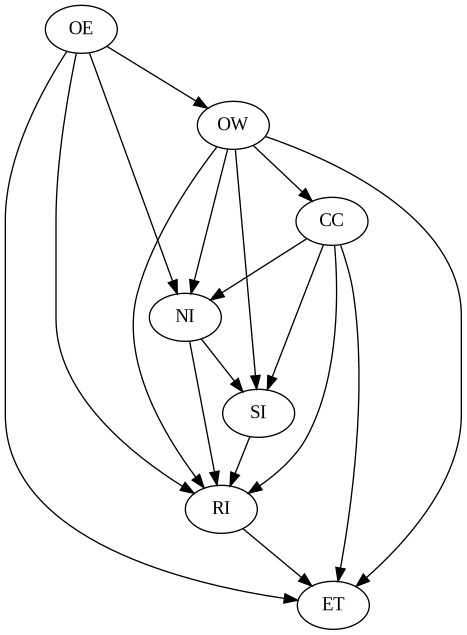

In [8]:
from IPython.display import Image
import networkx as nx

# Use pygraphviz (via networkx) for layout and saving to png
# Changed 'graph' to 'causal_graph' to match your defined graph variable
p = nx.drawing.nx_pydot.to_pydot(causal_graph)
p.write_png('causal_graph_F.png')

# Display the saved image
Image('causal_graph_F.png')

In [11]:
from dowhy import CausalModel, gcm
import pandas as pd

In [12]:
from dowhy import gcm
causal_model = gcm.StructuralCausalModel(causal_graph)

In [15]:
# Set causal mechanisms for each node
causal_model.set_causal_mechanism('OE', gcm.EmpiricalDistribution())
causal_model.set_causal_mechanism('CC', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('RI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('NI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('SI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('OW', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('ET', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))

# Now fit the model , Fitting the SCM to the data
gcm.fit(causal_model, df)


Fitting causal mechanism of node ET: 100%|██████████| 7/7 [00:00<00:00, 42.62it/s]


Test permutations of given graph: 100%|██████████| 50/50 [00:41<00:00,  1.20it/s]


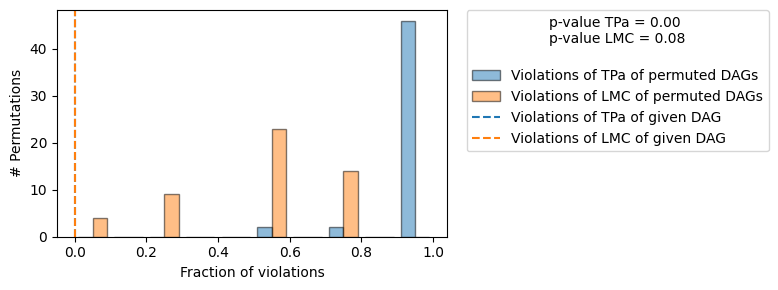

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

In [16]:
print(gcm.evaluate_causal_model(causal_model, df))

In [ ]:
model=CausalModel(
        data = df,
        treatment='RI',
        outcome='ET',
        graph=causal_graph,  # Pass the causal_graph variable directly
        instruments=['CC', 'OE', 'OW']
        )
#model.view_model(layout="dot")
model.view_model(file_name="causal_model.png")

In [ ]:
identified_estimand = model.identify_effect()
print(identified_estimand)

In [ ]:
estimate= model.estimate_effect(
 identified_estimand,
 method_name='backdoor.linear_regression',
 confidence_intervals=True,
  test_significance=True
)

print(f'Estimate of causal effect: {estimate}')

In [ ]:
# For SI
model=CausalModel(
        data = df,
        treatment='SI',
        outcome='ET',
        graph=causal_graph,  # Pass the causal_graph variable directly
        instruments=['CC', 'NI', 'OW']
        )
model.view_model(layout="dot")
model.view_model(file_name="causal_model.png")

In [ ]:
identified_estimand = model.identify_effect()
print(identified_estimand)

In [ ]:
estimate= model.estimate_effect(
 identified_estimand,
 method_name='backdoor.linear_regression',
 confidence_intervals=True,
  test_significance=True
)

print(f'Estimate of causal effect: {estimate}')

In [ ]:
import statsmodels.api as sm
est = model.estimate_effect(identified_estimand,
        method_name='backdoor.generalized_linear_model',
        method_params={'glm_family': sm.families.Poisson()},
        control_value=0, treatment_value=1, effect_modifiers=[])

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import Image

# Create the graph from correctly formatted Python tuples
edges = [
    ('OE', 'OW'),
    ('OW', 'CC'),
    ('CC', 'NI'), ('CC', 'SI'), ('CC', 'RI'),
    ('OW', 'SI'),
    ('OE', 'RI'),
    ('NI', 'RI'), ('SI', 'RI'),
    ('RI', 'ET'),
    ('CC', 'ET'), ('OW', 'ET'), ('OE', 'ET')
]
graph = nx.DiGraph(edges)

# Use pygraphviz (via networkx) for layout and saving to png
p = nx.drawing.nx_pydot.to_pydot(graph)

# Customize edge colors matching your configuration
for edge in p.get_edges():
    if edge.get_source() == 'RI' and edge.get_destination() == 'ET':
        edge.set_color('#2B6CB0')
        edge.set_penwidth(2.2)

p.write_png('causal_graph.png')

# Display the saved image
Image('causal_graph.png')

In [ ]:
# fINAL gRAPH for Openstack
import pandas as pd
import networkx as nx
import dowhy.gcm as gcm
from dowhy.gcm.falsify import falsify_graph

# 1. Load the correct data file which has all required columns
url = ("https://raw.githubusercontent.com/ReshmiMaulik/"
       "Causal_Inference-for-Openstack/main/workingdata_openstack_newET.csv")
raw = pd.read_csv(url)
print(raw.shape)          # expected: (13248, ...)

# 2. Keep only usable bugs (resolution and creation dates present, not a duplicate record)
df = raw[raw['usable'].astype(str) == 'True'].copy()
print(len(df))            # expected: 12624


# Rename 'Pr' to 'PR' if needed, though PR is not in selected_cols
#df1 = df1.rename(columns={'ET_days': 'ET'})
df = df.rename(columns={
    'ET_days': 'ET',
    'Contributors': 'CC',
    'OwnerEngagement': 'OE',
    'OwnerWorkload': 'OW',
    'NewInteractions': 'NI',
    'SeasonedInteractions': 'SI',
    'RepeatedInteractions': 'RI',
})

# Ensure all required columns are in the dataframe
selected_cols = ['CC', 'ET', 'OE', 'OW', 'RI', 'SI', 'NI']
data_subset = df[selected_cols].dropna().copy()

# 2. Define the causal graph structure
edges = [
    ('OE', 'OW'),                              # owner variables
    ('OW', 'CC'),
    ('CC', 'NI'), ('CC', 'SI'), ('CC', 'RI'),  # sum identity: NI + FI + SI + RI = CC(CC-1)/2
    ('OE', 'NI'), ('OW', 'NI'),                # owner influence on who joins
    ('OW', 'SI'),
    ('OE', 'RI'), ('OW', 'RI'),
    ('NI', 'SI'), ('NI', 'RI'), ('SI', 'RI'),  # interaction types compete for a fixed number of pairs
    ('RI', 'ET'),                              # effect of interest (RQ1)
    ('CC', 'ET'), ('OW', 'ET'), ('OE', 'ET')
]
causal_graph = nx.DiGraph(edges)



In [ ]:
# 4. Analysis data frame: covariates on the log scale, as in the paper's specification
data = df[['issue_id', 'ET', 'RI', 'SI', 'NI', 'CC', 'OE', 'OW']].copy()
data['CC'] = np.log(data['CC'])
data['OE'] = np.log1p(data['OE'])
data['OW'] = np.log1p(data['OW'])
data['NI'] = np.log1p(data['NI'])

data.head()

In [ ]:
from IPython.display import Image
import networkx as nx

# Use pygraphviz (via networkx) for layout and saving to png
# Changed 'graph' to 'causal_graph' to match your defined graph variable
p = nx.drawing.nx_pydot.to_pydot(causal_graph)
p.write_png('causal_graph_F.png')

# Display the saved image
Image('causal_graph_F.png')

In [ ]:
# Set causal mechanisms for each node
causal_model.set_causal_mechanism('OE', gcm.EmpiricalDistribution())
causal_model.set_causal_mechanism('CC', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('RI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('NI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('SI', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('OW', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))
causal_model.set_causal_mechanism('ET', gcm.AdditiveNoiseModel(gcm.ml.create_linear_regressor()))

# Now fit the model , Fitting the SCM to the data
gcm.fit(causal_model, df)


In [ ]:
print(gcm.evaluate_causal_model(causal_model, df))

The setup used to evaluate the performance of your causal mechanisms, their invertibility assumptions, the overall average KL divergence, and the graph structure (using the 50 random permutations shown in your logs) is powered by DoWhy's Graphical Causal Model (GCM) framework.

Specifically, the function gcm.evaluate_causal_model(causal_model, df) performs these checks. It evaluates:

Causal Mechanisms (using MSE, $R^2$$R^2$, and CRPS): To test how well the chosen structural equations fit your data.
Generated Distribution (KL Divergence): To compare the joint distribution generated by the fitted SCM with the observed dataset.
Causal Graph Structure (via falsify_graph): To check the Local Markov Conditions (LMCs) against permuted graphs to test if the DAG is statistically rejected.


In [ ]:
model=CausalModel(
        data = data,
        treatment='RI',
        outcome='ET',
        graph=causal_graph,  # Pass the causal_graph variable directly
        instruments=['CC', 'OE', 'OW']
        )
model.view_model(layout="dot")
model.view_model(file_name="causal_model.png")

In [ ]:
identified_estimand = model.identify_effect()
print(identified_estimand)

In [ ]:
estimate= model.estimate_effect(
 identified_estimand,
 method_name='backdoor.linear_regression',
 confidence_intervals=True,
  test_significance=True
)

print(f'Estimate of causal effect: {estimate}')

In [ ]:
import statsmodels.formula.api as smf
fit = smf.ols('ET ~ RI + OE + CC + OW', data).fit(cov_type='HC1')
print(fit.params['RI'], fit.conf_int().loc['RI'].values, fit.pvalues['RI'])

Causal inference of SI on ET for OpenStack

In [ ]:
model=CausalModel(
        data = df,
        treatment='SI',
        outcome='ET',
        graph=causal_graph,  # Pass the causal_graph variable directly
        instruments=['CC', 'OE', 'OW']
        )
model.view_model(layout="dot")
model.view_model(file_name="causal_model.png")

In [ ]:
identified_estimand = model.identify_effect()
print(identified_estimand)

In [ ]:
estimate= model.estimate_effect(
 identified_estimand,
 method_name='backdoor.linear_regression',
 confidence_intervals=True,
  test_significance=True
)

print(f'Estimate of causal effect: {estimate}')

In [ ]:
import statsmodels.formula.api as smf
fit = smf.ols('ET ~ SI + NI + CC + OW', data).fit(cov_type='HC1')
print(fit.params['SI'], fit.conf_int().loc['SI'].values, fit.pvalues['SI'])

**Causal Effect**

In [17]:
# load the data from GitHub
import numpy as np, pandas as pd, warnings
import statsmodels.formula.api as smf
from scipy.stats import t as tdist
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
warnings.filterwarnings('ignore')


BASE = 'https://raw.githubusercontent.com/ReshmiMaulik/Causal_Inference-for-Openstack/main/'
FILES = {'openstack': BASE + 'workingdata_openstack_newET.csv',
         'eclipse':   BASE + 'workingdata_eclipse_newET.csv'}
NAMES = {'openstack': 'OpenStack', 'eclipse': 'Eclipse'}
RENAME = {'ET_days': 'ET', 'Contributors': 'CC', 'OwnerEngagement': 'OE', 'OwnerWorkload': 'OW',
          'NewInteractions': 'NI', 'SeasonedInteractions': 'SI', 'RepeatedInteractions': 'RI'}
VARS = ['OE', 'OW', 'CC', 'NI', 'SI', 'RI', 'ET']

def load(system):
    d = pd.read_csv(FILES[system], encoding='latin-1')
    d = d[d['usable'].astype(str) == 'True'].rename(columns=RENAME)     # keep only usable rows
    d = d[VARS].astype(float).reset_index(drop=True)
    # covariates on the scale used throughout the paper; treatments (RI, SI) and outcome (ET, days) untransformed
    d['CC'] = np.log(d['CC']); d['OE'] = np.log1p(d['OE']); d['OW'] = np.log1p(d['OW']); d['NI'] = np.log1p(d['NI'])
    return d

data = {s: load(s) for s in FILES}
for s, d in data.items():
    print(f'{NAMES[s]}: {len(d):,} usable bugs')        # expected: OpenStack 25,321; Eclipse 12,624

# Adjustment sets from the backdoor criterion under graph A (Table 8)
ADJ = {'RI': ['CC', 'OE', 'OW'], 'SI': ['CC', 'NI', 'OW']}
BENCHMARKS = ['CC', 'OW']          # observed covariates used as benchmarks for an unmeasured confounder

OpenStack: 25,321 usable bugs
Eclipse: 12,624 usable bugs


In [18]:
# Cell 3 - Cinelli & Hazlett
def partial_r2(t_stat, dof):
    """Partial R^2 of a regressor from its t-statistic."""
    return t_stat**2 / (t_stat**2 + dof)

def robustness_value(t_stat, dof, q=1.0, alpha=None):
    """RV_q: share of residual variance of treatment AND outcome a confounder must explain to reduce the
    estimate by 100q% (alpha=None), or to make it statistically insignificant at level alpha."""
    f = q * abs(t_stat) / np.sqrt(dof)
    if alpha is not None:
        f -= tdist.ppf(1 - alpha / 2, dof - 1) / np.sqrt(dof - 1)
    return 0.0 if f <= 0 else 0.5 * (np.sqrt(f**4 + 4 * f**2) - f**2)

def adjusted_estimate(est, se, dof, r2dz, r2yz):
    """Estimate and 95% CI after removing the bias of a confounder with partial R^2 r2dz (with treatment)
    and r2yz (with outcome), assuming the confounder pushes the estimate away from zero."""
    bias = se * np.sqrt(dof) * np.sqrt(r2yz * r2dz / (1 - r2dz))
    adj = est - np.sign(est) * bias
    se_adj = se * np.sqrt((1 - r2yz) / (1 - r2dz)) * np.sqrt(dof / (dof - 1))
    c = tdist.ppf(0.975, dof - 1)
    return adj, adj - c * se_adj, adj + c * se_adj

def benchmark_bounds(r2dxj, r2yxj, k=1):
    """Partial R^2 of a confounder k times as strongly related to treatment and outcome as covariate X_j."""
    r2dz = k * r2dxj / (1 - r2dxj)
    r2zxj = k * r2dxj**2 / ((1 - k * r2dxj) * (1 - r2dxj))
    r2yz = min(1.0, ((np.sqrt(k) + np.sqrt(r2zxj)) / np.sqrt(1 - r2zxj))**2 * (r2yxj / (1 - r2yxj)))
    return r2dz, r2yz

In [19]:
# Run the analysis for both systems and both treatments
results, rows = {}, []
for s, d in data.items():
    for T, Z in ADJ.items():
        out_model = smf.ols(f'ET ~ {T} + ' + ' + '.join(Z), data=d).fit()      # outcome model (linear, days)
        trt_model = smf.ols(f'{T} ~ ' + ' + '.join(Z), data=d).fit()           # treatment model (for benchmarks)
        est, se, dof = out_model.params[T], out_model.bse[T], out_model.df_resid
        t_stat = est / se
        res = {'est': est, 'se': se, 'dof': dof, 't': t_stat,
               'r2yd_x': partial_r2(t_stat, dof),
               'RV': robustness_value(t_stat, dof),
               'RV_a05': robustness_value(t_stat, dof, alpha=0.05),
               'bench': {}}
        for b in BENCHMARKS:
            r2dxj = partial_r2(trt_model.tvalues[b], trt_model.df_resid)   # benchmark's partial R^2 with treatment
            r2yxj = partial_r2(out_model.tvalues[b], dof)                  # benchmark's partial R^2 with outcome
            for k in [1, 2, 3]:
                r2dz, r2yz = benchmark_bounds(r2dxj, r2yxj, k)
                if not (0 <= r2dz < 1 and 0 <= r2yz < 1):
                    res['bench'][f'{k}x {b}'] = dict(r2dz=r2dz, r2yz=r2yz, adj=None, lo=None, hi=None)
                    continue
                adj, lo, hi = adjusted_estimate(est, se, dof, r2dz, r2yz)
                res['bench'][f'{k}x {b}'] = dict(r2dz=r2dz, r2yz=r2yz, adj=adj, lo=lo, hi=hi)
        results[(s, T)] = res
        fmt = lambda v: 'not attainable' if v['adj'] is None else f"{v['adj']:.3f} [{v['lo']:.3f}, {v['hi']:.3f}]"
        rows.append({'System': NAMES[s], 'Treatment': T,
                     'Estimate (days)': round(est, 3), 'SE': round(se, 3), 't': round(t_stat, 2),
                     'Partial R2 (T,Y|Z)': round(res['r2yd_x'], 4),
                     'RV': round(res['RV'], 3), 'RV (alpha=0.05)': round(res['RV_a05'], 3),
                     'As strong as OW': fmt(res['bench']['1x OW']),
                     'As strong as CC': fmt(res['bench']['1x CC'])})

summary = pd.DataFrame(rows)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
summary
# Expected: RV = 0.055 / 0.092 / 0.030 / 0.016 (OpenStack RI, OpenStack SI, Eclipse RI, Eclipse SI)

,System,Treatment,Estimate (days),SE,t,"Partial R2 (T,Y|Z)",RV,RV (alpha=0.05),As strong as OW,As strong as CC
0,OpenStack,RI,-0.464,0.052,-8.93,0.0031,0.055,0.043,"-0.400 [-0.502, -0.299]",not attainable
1,OpenStack,SI,1.976,0.128,15.42,0.0093,0.092,0.081,"1.950 [1.700, 2.200]","0.004 [-0.277, 0.284]"
2,Eclipse,RI,-0.062,0.018,-3.46,0.0010,0.030,0.013,"-0.060 [-0.095, -0.025]","0.102 [0.068, 0.137]"
3,Eclipse,SI,-0.107,0.057,-1.87,0.0003,0.016,0.000,"-0.098 [-0.210, 0.014]","0.276 [0.165, 0.387]"


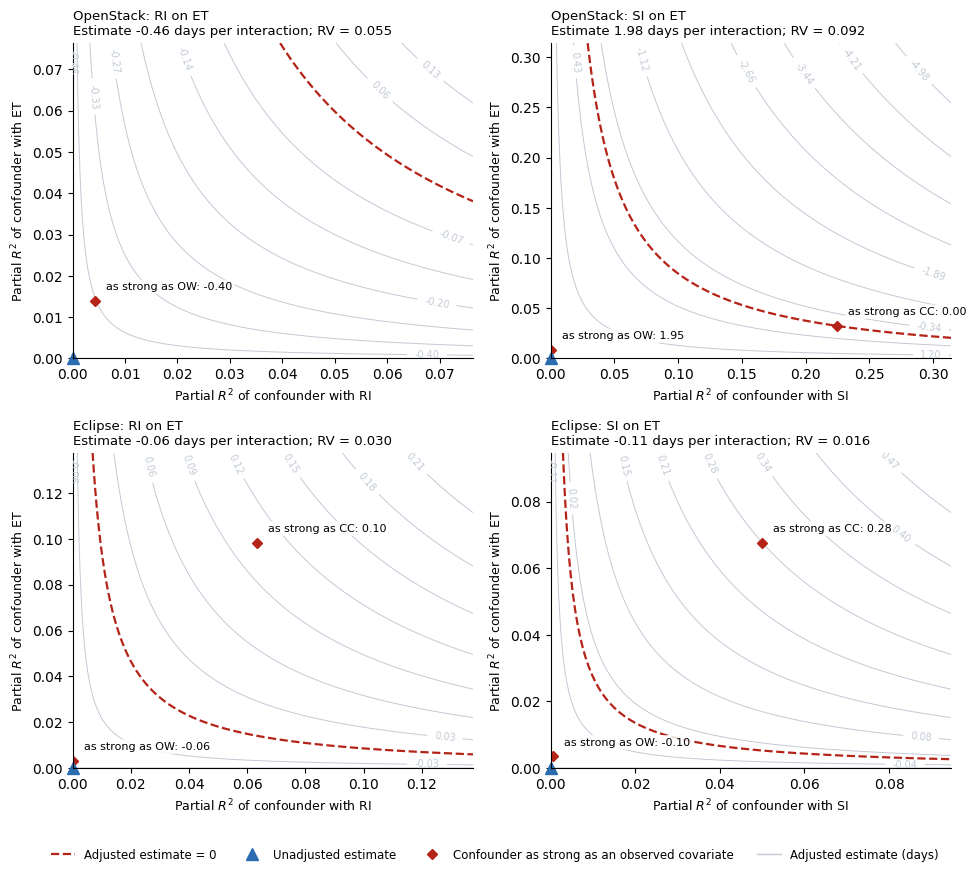

In [20]:
# Sensitivity contour plots
fig, axs = plt.subplots(2, 2, figsize=(10, 8.6))
for i, s in enumerate(FILES):
    for j, T in enumerate(ADJ):
        r = results[(s, T)]; ax = axs[i, j]
        est, se, dof = r['est'], r['se'], r['dof']
        shown = [v for k, v in r['bench'].items() if k.startswith('1x') and v['adj'] is not None]
        lim = min(0.6, max(0.02, 1.4 * max([r['RV']] + [v['r2dz'] for v in shown] + [v['r2yz'] for v in shown])))
        g = np.linspace(0, lim, 201); X, Y = np.meshgrid(g, g)
        Zs = est - np.sign(est) * se * np.sqrt(dof) * np.sqrt(Y * X / (1 - X))   # adjusted estimate surface
        levels = [l for l in np.linspace(Zs.min(), Zs.max(), 11) if abs(l) > 0.03 * abs(Zs).max()]
        cs = ax.contour(X, Y, Zs, levels=levels, colors='#C3CAD4', linewidths=0.7, linestyles='solid')
        ax.clabel(cs, fontsize=7, fmt='%.2f')
        ax.contour(X, Y, Zs, levels=[0], colors='#B42318', linewidths=1.6, linestyles='--')
        for k, v in r['bench'].items():
            if k.startswith('1x') and v['adj'] is not None and v['r2dz'] < lim and v['r2yz'] < lim:
                ax.plot(v['r2dz'], v['r2yz'], marker='D', color='#B42318', ms=5)
                ax.annotate(f"{k.replace('1x ', 'as strong as ')}: {v['adj']:.2f}", (v['r2dz'], v['r2yz']),
                            textcoords='offset points', xytext=(8, 8), fontsize=8,
                            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))
        ax.plot(0, 0, marker='^', color='#2B6CB0', ms=8, clip_on=False)
        ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_title(f"{NAMES[s]}: {T} on ET\nEstimate {est:.2f} days per interaction; RV = {r['RV']:.3f}",
                     fontsize=9.5, loc='left')
        ax.set_xlabel(f'Partial $R^2$ of confounder with {T}', fontsize=9)
        ax.set_ylabel('Partial $R^2$ of confounder with ET', fontsize=9)
        for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
fig.legend([Line2D([], [], color='#B42318', ls='--', lw=1.6),
            Line2D([], [], marker='^', color='#2B6CB0', ls='', ms=8),
            Line2D([], [], marker='D', color='#B42318', ls='', ms=5),
            Line2D([], [], color='#C3CAD4', lw=1)],
           ['Adjusted estimate = 0', 'Unadjusted estimate', 'Confounder as strong as an observed covariate',
            'Adjusted estimate (days)'], loc='lower center', ncol=4, frameon=False, fontsize=8.5,
           bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig('Figure_sensitivity.png', dpi=300, bbox_inches='tight')
fig.savefig('Figure_sensitivity.pdf', bbox_inches='tight')
plt.show()

In [23]:
def load(system):
    d = pd.read_csv(FILES[system], encoding='latin-1')
    d = d[d['usable'].astype(str) == 'True'].rename(columns=RENAME)      # keep only usable rows
    d = d[VARS].astype(float).reset_index(drop=True)
    # covariates on the scale used in the paper; treatments (RI, SI) and outcome (ET, days) untransformed
    d['CC'] = np.log(d['CC']); d['OE'] = np.log1p(d['OE']); d['OW'] = np.log1p(d['OW']); d['NI'] = np.log1p(d['NI'])
    return d

data = {s: load(s) for s in FILES}
for s, d in data.items():
    print(f'{NAMES[s]}: {len(d):,} usable bugs')          # expected: OpenStack 25,321; Eclipse 12,624

OpenStack: 25,321 usable bugs
Eclipse: 12,624 usable bugs


In [21]:
# Poisson regression with log link: % change per interaction, 95% CI, p (HC1 robust SEs)
def poisson_effect(d, T, Z):
    """E[ET | T, Z] = exp(b0 + b_T*T + b_Z*Z).  theta_T = exp(b_T); % change = 100*(exp(b_T) - 1)."""
    fit = smf.glm(f'ET ~ {T} + ' + ' + '.join(Z), data=d, family=sm.families.Poisson()).fit(cov_type='HC1')
    b, se = fit.params[T], fit.bse[T]
    return fit, {'pct': 100 * (np.exp(b) - 1),
                 'pct_lo': 100 * (np.exp(b - 1.96 * se) - 1),
                 'pct_hi': 100 * (np.exp(b + 1.96 * se) - 1),
                 'p': fit.pvalues[T]}

In [24]:
# ATE from 0 to 1 interaction, in days (backdoor adjustment / g-computation)
def ate_0_to_1(fit, d, T):
    """E[ET | do(T=1)] - E[ET | do(T=0)] = mean over all bugs of the predicted ET with T set to 1
    minus the predicted ET with T set to 0 (Equation 5, with the Poisson model for E[ET | T, Z])."""
    return fit.predict(d.assign(**{T: 1})).mean() - fit.predict(d.assign(**{T: 0})).mean()

def ate_0_to_1_dowhy(d, T, Z):
    """The same quantity with DoWhy's backdoor.generalized_linear_model estimator (effect modifiers disabled)."""
    m = CausalModel(data=d, treatment=T, outcome='ET', graph=nx.DiGraph(EDGES_A), effect_modifiers=[])
    ie = m.identify_effect(proceed_when_unidentifiable=True)
    ie.set_backdoor_variables(Z)
    est = m.estimate_effect(ie, method_name='backdoor.generalized_linear_model',
                            method_params={'glm_family': sm.families.Poisson()},
                            control_value=0, treatment_value=1, effect_modifiers=[])
    return est.value

In [27]:
def load(system):
    d = pd.read_csv(FILES[system], encoding='latin-1')
    d = d[d['usable'].astype(str) == 'True'].rename(columns=RENAME)      # keep only usable rows
    d = d[VARS].astype(float).reset_index(drop=True)
    # covariates on the scale used in the paper; treatments (RI, SI) and outcome (ET, days) untransformed
    d['CC'] = np.log(d['CC']); d['OE'] = np.log1p(d['OE']); d['OW'] = np.log1p(d['OW']); d['NI'] = np.log1p(d['NI'])
    return d

data = {s: load(s) for s in FILES}
for s, d in data.items():
    print(f'{NAMES[s]}: {len(d):,} usable bugs')          # expected: OpenStack 25,321; Eclipse 12,624

# Graph A (Figure 2) and the backdoor adjustment sets (Table 8)
EDGES_A = [('OE','OW'), ('OW','CC'),
           ('CC','NI'), ('CC','SI'), ('CC','RI'),
           ('OE','NI'), ('OW','NI'), ('OW','SI'), ('OE','RI'), ('OW','RI'),
           ('NI','SI'), ('NI','RI'), ('SI','RI'),
           ('RI','ET'), ('CC','ET'), ('OW','ET'), ('OE','ET')]
ADJ = {'RI': ['CC', 'OE', 'OW'], 'SI': ['CC', 'NI', 'OW']}

OpenStack: 25,321 usable bugs
Eclipse: 12,624 usable bugs


In [29]:
from statsmodels.stats.multitest import multipletests

# Run all four effects, then the Holm correction over the four p-values
rows = []
for s, d in data.items():
    for T, Z in ADJ.items():
        fit, r = poisson_effect(d, T, Z)
        lin = smf.ols(f'ET ~ {T} + ' + ' + '.join(Z), data=d).fit(cov_type='HC1')     # secondary, days
        rows.append({'System': NAMES[s], 'Treatment': T, 'n': len(d), 'Adjustment set': ', '.join(Z),
                     '% change per interaction': r['pct'], 'CI low': r['pct_lo'], 'CI high': r['pct_hi'],
                     'p': r['p'],
                     'ATE 0->1 (days)': ate_0_to_1(fit, d, T),
                     'ATE 0->1, DoWhy (days)': ate_0_to_1_dowhy(d, T, Z),
                     'Linear: days per interaction': lin.params[T],
                     'Linear CI low': lin.conf_int().loc[T, 0], 'Linear CI high': lin.conf_int().loc[T, 1],
                     'Linear p': lin.pvalues[T]})
res = pd.DataFrame(rows)

# Holm (step-down Bonferroni) over the four primary tests
reject, p_holm, _, _ = multipletests(res['p'], alpha=0.05, method='holm')
res['Holm-adjusted p'] = p_holm
res['Significant after Holm'] = reject

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
res.round(4)
# Expected (% change, ATE 0->1 days): OpenStack RI -1.33, -0.611; OpenStack SI +0.68, 0.256;
#                                     Eclipse RI -0.12, -0.142;  Eclipse SI -0.12, -0.144.  Largest Holm p = 0.0068.

,System,Treatment,n,Adjustment set,% change per interaction,CI low,CI high,p,ATE 0->1 (days),"ATE 0->1, DoWhy (days)",Linear: days per interaction,Linear CI low,Linear CI high,Linear p,Holm-adjusted p,Significant after Holm
0,OpenStack,RI,25321,"CC, OE, OW",-1.3255,-1.9609,-0.6860,0.0001,-0.6109,-0.6109,-0.4642,-0.7351,-0.1932,0.0008,0.0002,True
1,OpenStack,SI,25321,"CC, NI, OW",0.6808,0.3817,0.9808,0.0000,0.2560,0.2560,1.9758,1.3239,2.6277,0.0000,0.0000,True
2,Eclipse,RI,12624,"CC, OE, OW",-0.1183,-0.2040,-0.0326,0.0068,-0.1425,-0.1425,-0.0620,-0.0946,-0.0294,0.0002,0.0068,True
3,Eclipse,SI,12624,"CC, NI, OW",-0.1218,-0.1938,-0.0498,0.0009,-0.1443,-0.1443,-0.1069,-0.2777,0.0638,0.2196,0.0018,True


In [30]:
# The Holm correction by hand (same result as multipletests)
def holm(pvals):
    """Sort p ascending; multiply the i-th smallest (i = 0..m-1) by (m - i); enforce monotonicity; cap at 1."""
    p = np.asarray(pvals, float); m = len(p); order = np.argsort(p)
    adj = np.empty(m); running = 0.0
    for i, k in enumerate(order):
        running = max(running, min(1.0, (m - i) * p[k]))
        adj[k] = running
    return adj

print(np.allclose(holm(res['p']), res['Holm-adjusted p']))   # True

True


# OpenStack and Eclipse, treatments RI and SI, Causal graph. Poisson regression with log link.

In [31]:
# % change in expected ET per additional interaction as the adjustment set is built up
# Only the last row of each block (the full backdoor set) is a causal estimate under graph A;
# the others show how the estimate moves, in particular when CC enters.
STEPS = {'RI': [[], ['OE', 'OW'], ['CC', 'OE', 'OW']],
         'SI': [[], ['NI', 'OW'], ['CC', 'NI', 'OW']]}

def pct_change(d, T, Z):
    f = f'ET ~ {T}' + ('' if not Z else ' + ' + ' + '.join(Z))
    fit = smf.glm(f, data=d, family=sm.families.Poisson()).fit(cov_type='HC1')
    b, se = fit.params[T], fit.bse[T]
    return 100 * (np.exp(b) - 1), 100 * (np.exp(b - 1.96 * se) - 1), 100 * (np.exp(b + 1.96 * se) - 1), fit.pvalues[T]

rows = []
for T, steps in STEPS.items():
    for Z in steps:
        row = {'Treatment': T, 'Covariates': 'None' if not Z else ', '.join(Z) + (' (adjustment set)' if Z == ADJ[T] else '')}
        for s, d in data.items():
            est, lo, hi, p = pct_change(d, T, Z)
            row[NAMES[s]] = est
            row[f'{NAMES[s]} 95% CI'] = f'[{lo:+.2f}, {hi:+.2f}]'
        rows.append(row)
table10 = pd.DataFrame(rows)
table10.to_csv('table10_adjustment_steps.csv', index=False)
table10.round(2)
# Expected: RI  OpenStack +0.76, +0.80, -1.33 | Eclipse +0.02, +0.02, -0.12
#           SI  OpenStack +2.24, +2.06, +0.68 | Eclipse +0.14, +0.02, -0.12


,Treatment,Covariates,OpenStack,OpenStack 95% CI,Eclipse,Eclipse 95% CI
0,RI,None,0.76,"[+0.64, +0.88]",0.02,"[+0.01, +0.03]"
1,RI,"OE, OW",0.80,"[+0.68, +0.92]",0.02,"[+0.01, +0.03]"
2,RI,"CC, OE, OW (adjustment set)",-1.33,"[-1.96, -0.69]",-0.12,"[-0.20, -0.03]"
3,SI,None,2.24,"[+1.87, +2.62]",0.14,"[+0.11, +0.18]"
4,SI,"NI, OW",2.06,"[+1.67, +2.45]",0.02,"[-0.03, +0.06]"
5,SI,"CC, NI, OW (adjustment set)",0.68,"[+0.38, +0.98]",-0.12,"[-0.19, -0.05]"


In [33]:
# DoWhy refutation tests of the ATE 0 -> 1 (days), 100 simulations each
NSIM = 100            # set to e.g. 10 for a quick trial run
SEED = 7
REFUTERS = [('RCC', dict(method_name='random_common_cause')),
            ('DSR', dict(method_name='data_subset_refuter', subset_fraction=0.8)),
            ('BR',  dict(method_name='bootstrap_refuter')),
            ('PT',  dict(method_name='placebo_treatment_refuter', placebo_type='permute'))]

def fit_model(d, T, Z):
    m = CausalModel(data=d, treatment=T, outcome='ET', graph=nx.DiGraph(EDGES_A), effect_modifiers=[])
    ie = m.identify_effect(proceed_when_unidentifiable=True)
    ie.set_backdoor_variables(Z)                                  # adjustment set of Table 8
    est = m.estimate_effect(ie, method_name='backdoor.generalized_linear_model',
                            method_params={'glm_family': sm.families.Poisson()},
                            control_value=0, treatment_value=1, effect_modifiers=[])
    return m, ie, est

def refute(d, T, Z):
    m, ie, est = fit_model(d, T, Z)
    out = {'ATE 0->1 (days)': est.value}
    for name, kw in REFUTERS:
        m, ie, est = fit_model(d, T, Z)        # fresh model for each refuter, so results do not depend on their order
        np.random.seed(SEED)
        r = m.refute_estimate(ie, est, num_simulations=NSIM, random_seed=SEED, **kw)
        p = r.refutation_result.get('p_value') if isinstance(r.refutation_result, dict) else None
        out[f'{name} new effect'] = r.new_effect
        out[f'{name} p'] = p
    return out



In [34]:
refute_rows = []
for s, d in data.items():
    for T, Z in ADJ.items():
        print(f"Running refutations for {NAMES[s]} - {T}...")
        out = refute(d, T, Z)
        row = {
            'System': NAMES[s],
            'Treatment': T,
            'ATE 0->1 (days)': out['ATE 0->1 (days)'],
            'RCC new effect': out['RCC new effect'],
            'RCC p': out['RCC p'],
            'DSR new effect': out['DSR new effect'],
            'DSR p': out['DSR p'],
            'BR new effect': out['BR new effect'],
            'BR p': out['BR p'],
            'PT new effect': out['PT new effect'],
            'PT p': out['PT p']
        }
        refute_rows.append(row)

refute_summary = pd.DataFrame(refute_rows)
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', 15)
display(refute_summary.round(4))

Running refutations for OpenStack - RI...
Running refutations for OpenStack - SI...
Running refutations for Eclipse - RI...
Running refutations for Eclipse - SI...


,System,Treatment,ATE 0->1 (days),RCC new effect,RCC p,DSR new effect,DSR p,BR new effect,BR p,PT new effect,PT p
0,OpenStack,RI,-0.6109,-0.6109,0.98,-0.6127,0.88,-0.6276,0.96,-0.0032,0.88
1,OpenStack,SI,0.2560,0.2562,0.98,0.2592,0.96,0.2766,0.78,-0.0361,0.72
2,Eclipse,RI,-0.1425,-0.1425,0.86,-0.1433,0.86,-0.1556,0.98,-0.0147,0.74
3,Eclipse,SI,-0.1443,-0.1443,0.98,-0.1474,0.84,-0.1561,0.88,-0.0133,0.88
